# Dana’s Bakery — Homework 2
A deterministic LangGraph order processor. No model, API key, or AI service is used.
Run **Runtime → Run all** in a fresh Google Colab session. Each order uses the same initial inventory.

Prices are in shekels. Product, weekday, and city text is stripped and case-normalized. All four form fields are required; an empty city means pickup. Quantities must be positive Python integers (booleans are rejected).

In [1]:
%pip -q install langgraph==1.2.20


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## State and catalog
Separate input and output schemas keep the public result limited to the six required keys. Decimal arithmetic preserves accurate prices.

In [2]:
from decimal import Decimal
from typing import TypedDict, Any
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

class OrderInput(TypedDict):
    item: Any
    quantity: Any
    day: Any
    city: Any

class OrderOutput(TypedDict):
    status: str
    item: str | None
    delivery: str
    total: float
    message: str
    steps: list[str]

class OrderState(OrderInput, total=False):
    status: str
    delivery: str
    total: float
    message: str
    steps: list[str]
    requested_item: str
    attempts: int
    available: bool
    reason: str
    subtotal: Decimal
    discount: Decimal
    delivery_charge: Decimal
    notes: list[str]

CATALOG = {
    "challah": (Decimal("18"), 10),
    "babka": (Decimal("45"), 0),
    "rugelach": (Decimal("30"), 3),
    "sourdough": (Decimal("25"), 4),
}
NEXT = {"babka": "rugelach", "rugelach": "sourdough", "sourdough": "challah"}
DAYS = {"monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"}

## Processing nodes
Validation precedes inventory access. Substitution tries one next product per visit, with a strict two-suggestion limit. Rejections go directly to the rejection node.

In [3]:
def validate(state):
    updates = dict(steps=["validate"], notes=[], attempts=0, status="processing",
                   subtotal=Decimal(0), discount=Decimal(0), delivery_charge=Decimal(0))
    reason = ""
    if any(key not in state for key in ("item", "quantity", "day", "city")):
        reason = "Please include item, quantity, day, and city (leave city empty for pickup)."
    elif not all(isinstance(state[key], str) for key in ("item", "day", "city")):
        reason = "Please use text for the product, day, and city."
    elif type(state["quantity"]) is not int or state["quantity"] <= 0:
        reason = "Please choose a positive whole-number quantity."
    else:
        item, day, city = (state[key].strip().lower() for key in ("item", "day", "city"))
        updates.update(item=item, requested_item=item, day=day, city=city)
        if item in {"croissant", "croissants"}:
            reason = "Croissants have been discontinued. Please choose an active bakery product."
        elif item not in CATALOG:
            reason = "We do not carry that product. Please choose challah, babka, rugelach, or sourdough."
        elif day not in DAYS:
            reason = "Please provide a valid weekday."
    updates.update(reason=reason, steps=["validate:invalid" if reason else "validate:valid"])
    return updates

def inventory(state):
    available = CATALOG[state["item"]][1] >= state["quantity"]
    return {"available": available,
            "steps": state["steps"] + [f"inventory:{'available' if available else 'insufficient'}"]}

def substitute(state):
    candidate = NEXT[state["item"]]
    attempt = state["attempts"] + 1
    available = CATALOG[candidate][1] >= state["quantity"]
    note = f"Suggestion {attempt}: {candidate} {'can' if available else 'cannot'} fill your full order."
    return {"item": candidate, "attempts": attempt, "available": available,
            "notes": state["notes"] + [note],
            "steps": state["steps"] + [f"substitute:{attempt}:{candidate}:{'available' if available else 'insufficient'}"]}

def discount(state):
    subtotal = CATALOG[state["item"]][0] * state["quantity"]
    eligible = subtotal > Decimal("150") and state["day"] != "friday"
    amount = (subtotal * Decimal("0.15")).quantize(Decimal("0.01")) if eligible else Decimal(0)
    decision = "applied" if eligible else ("friday" if state["day"] == "friday" else "below_or_at_threshold")
    return {"subtotal": subtotal, "discount": amount,
            "steps": state["steps"] + [f"discount:{decision}"]}

def delivery_decision(state):
    route = "delivery" if state["city"] == "jerusalem" else "pickup"
    return {"delivery": route, "steps": state["steps"] + [f"delivery_decision:{route}"]}

def delivery(state):
    return {"delivery_charge": Decimal("20"), "steps": state["steps"] + ["delivery:jerusalem"]}

def pickup(state):
    outside = bool(state["city"])
    note = "We deliver only in Jerusalem, so your order is ready for free pickup." if outside else "Enjoy free pickup at the bakery."
    return {"delivery_charge": Decimal(0), "notes": state["notes"] + [note],
            "steps": state["steps"] + ["pickup:outside_jerusalem" if outside else "pickup:empty_city"]}

def total(state):
    amount = state["subtotal"] - state["discount"] + state["delivery_charge"]
    return {"total": float(amount.quantize(Decimal("0.01"))), "status": "accepted",
            "steps": state["steps"] + ["total"]}

def message(state):
    parts = [f"Thank you for choosing Dana’s Bakery! Your {state['day'].title()} order of {state['quantity']} {state['item']} is confirmed."]
    parts += state["notes"]
    if state["attempts"]:
        parts.append(f"We replaced your {state['requested_item']} with {state['item']} at its own price.")
    parts.append(f"Baked goods: ₪{state['subtotal']:.2f}.")
    if state["discount"]:
        parts.append(f"Avi’s 15% discount saves you ₪{state['discount']:.2f}!")
    elif state["day"] == "friday":
        parts.append("Friday orders do not receive a discount.")
    if state["delivery"] == "delivery":
        parts.append("Jerusalem delivery is ₪20.00, with no discount on delivery.")
    parts.append(f"Your total is ₪{state['total']:.2f}. We look forward to baking for you!")
    return {"message": " ".join(parts), "steps": state["steps"] + ["message"]}

def reject(state):
    reason = state.get("reason") or "We cannot fill the full quantity within two alternatives or the substitution chain has ended. Your order is cancelled; you will not be charged."
    return {"status": "rejected", "item": None, "delivery": "pickup", "total": 0,
            "message": "Thank you for thinking of Dana’s Bakery! " + " ".join(state["notes"]) + " " + reason + " We hope to welcome you again soon.",
            "steps": state["steps"] + ["reject"]}

## Conditional routing and compilation

In [4]:
def stock_route(state):
    if state["available"]:
        return "discount"
    if state["attempts"] < 2 and state["item"] in NEXT:
        return "substitute"
    return "reject"

builder = StateGraph(OrderState, input_schema=OrderInput, output_schema=OrderOutput)
for name, function in [("validate", validate), ("inventory", inventory),
                       ("substitute", substitute), ("discount", discount),
                       ("delivery_decision", delivery_decision), ("delivery", delivery),
                       ("pickup", pickup), ("total", total), ("message", message), ("reject", reject)]:
    builder.add_node(name, function)
builder.add_edge(START, "validate")
builder.add_conditional_edges("validate", lambda s: "reject" if s["reason"] else "inventory",
                              {"reject": "reject", "inventory": "inventory"})
for node in ("inventory", "substitute"):
    builder.add_conditional_edges(node, stock_route,
                                  {"discount": "discount", "substitute": "substitute", "reject": "reject"})
builder.add_edge("discount", "delivery_decision")
builder.add_conditional_edges("delivery_decision", lambda s: s["delivery"],
                              {"delivery": "delivery", "pickup": "pickup"})
for node in ("delivery", "pickup"):
    builder.add_edge(node, "total")
builder.add_edge("total", "message")
builder.add_edge("message", END)
builder.add_edge("reject", END)
graph = builder.compile()

## Mermaid graph visualization
LangGraph generates the Mermaid diagram. The default PNG renderer uses mermaid.ink (diagram rendering only, no AI). If that site is unavailable, display the bundled image rendered from this same graph’s Mermaid source.

Remote Mermaid renderer unavailable (ValueError); showing the bundled Mermaid rendering.


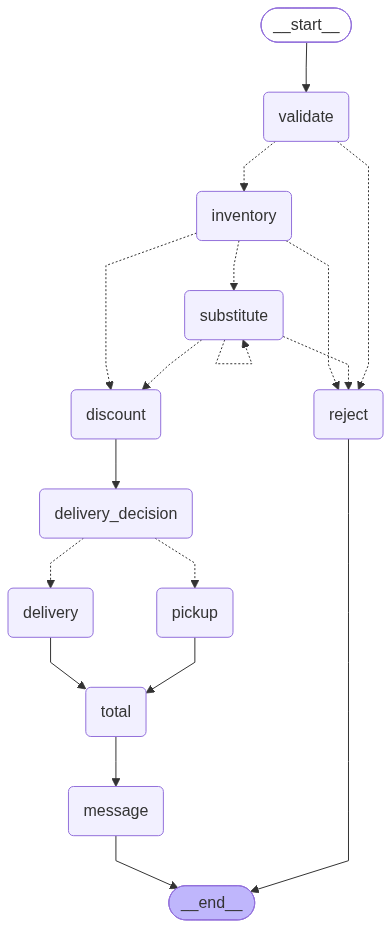

In [5]:
MERMAID_PNG_BASE64 = '...'

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print(f"Remote Mermaid renderer unavailable ({type(exc).__name__}); showing the bundled Mermaid rendering.")
    import base64
    display(Image(base64.b64decode(MERMAID_PNG_BASE64)))

## Test orders and automated assertions
Each case checks all six public outputs, exact prices, route decisions, substitution limits, and independent inventory. Invalid values include booleans, non-integers, missing fields, and malformed field types.

In [6]:
REQUIRED = {"status", "item", "delivery", "total", "message", "steps"}
cases = []
def case(name, item="challah", quantity=1, day="Thursday", city="", *, sold="challah", amount=18, route="pickup", marks=(), changes=None):
    order = dict(item=item, quantity=quantity, day=day, city=city)
    if changes:
        order.update(changes)
    cases.append((name, order, sold, amount, route, marks))

case("available + Jerusalem", quantity=2, city="Jerusalem", amount=56, route="delivery", marks=("inventory:available", "delivery:jerusalem"))
case("first alternative", "babka", 2, sold="rugelach", amount=60, marks=("substitute:1:rugelach:available",))
case("second alternative", "babka", 4, sold="sourdough", amount=100, marks=("substitute:1:rugelach:insufficient", "substitute:2:sourdough:available"))
case("cancel after two", "babka", 5, sold=None, amount=0, marks=("substitute:2:sourdough:insufficient", "reject"))
case("chain ends", "challah", 11, sold=None, amount=0, marks=("inventory:insufficient", "reject"))
case("chain ends after suggestion", "sourdough", 11, sold=None, amount=0, marks=("substitute:1:challah:insufficient", "reject"))
case("second substitution to challah", "rugelach", 5, amount=90, marks=("substitute:2:challah:available",))
case("first substitution to challah", "sourdough", 5, amount=90, marks=("substitute:1:challah:available",))
case("discount + undiscounted delivery", quantity=10, city="Jerusalem", amount=173, route="delivery", marks=("discount:applied",))
case("Friday exclusion", quantity=10, day="Friday", amount=180, marks=("discount:friday",))
case("outside city", city="Haifa", marks=("pickup:outside_jerusalem",))
case("empty city", marks=("pickup:empty_city", "discount:below_or_at_threshold"))
case("normalization", item=" CHALLAH ", city=" Jerusalem ", day=" THURSDAY ", amount=38, route="delivery")
case("unknown", "pizza", sold=None, amount=0)
for product in ("croissant", "croissants"):
    case(product, product, sold=None, amount=0)
for quantity in (0, -1, 1.5, "2", True, None, [], {}):
    case(f"invalid quantity {quantity!r}", quantity=quantity, sold=None, amount=0)
for field in ("item", "quantity", "day", "city"):
    order = dict(item="challah", quantity=1, day="Thursday", city="")
    del order[field]
    cases.append((f"missing {field}", order, None, 0, "pickup", ("validate:invalid",)))
for field in ("item", "day", "city"):
    case(f"malformed {field}", sold=None, amount=0, changes={field: []})
case("invalid weekday", day="Funday", sold=None, amount=0)
cases.append(("empty order", {}, None, 0, "pickup", ("validate:invalid",)))

results = []
for name, order, sold, amount, route, marks in cases:
    result = graph.invoke(order)
    assert set(result) == REQUIRED, (name, result)
    assert result["status"] == ("rejected" if sold is None else "accepted"), name
    assert result["item"] == sold, name
    assert result["total"] == amount, (name, result)
    assert result["delivery"] == route, name
    assert isinstance(result["total"], (int, float)), name
    assert result["message"] and "Dana" in result["message"], name
    assert all(mark in result["steps"] for mark in marks), (name, result["steps"])
    assert result["steps"][0].startswith("validate:"), name
    assert result["steps"][-1] == ("reject" if sold is None else "message"), name
    assert sum(step.startswith("substitute:") for step in result["steps"]) <= 2, name
    if sold is None:
        assert result["delivery"] == "pickup" and result["total"] == 0, name
    results.append(result)
    print(f"PASS {name}: {result['status']}, {result['item']}, ₪{result['total']:.2f}")

# No starting-stock order can produce exactly ₪150: test the pricing node
# independently, using 5 rugelach, without changing stock or the catalog.
threshold = discount({"item": "rugelach", "quantity": 5, "day": "thursday", "steps": []})
assert threshold["subtotal"] == Decimal("150") and threshold["discount"] == 0
fractional = discount({"item": "challah", "quantity": 9, "day": "thursday", "steps": []})
assert fractional["discount"] == Decimal("24.30")
assert graph.invoke(dict(item="challah", quantity=9, day="Thursday", city=""))["total"] == 137.70
order = dict(item="sourdough", quantity=4, day="Thursday", city="")
assert graph.invoke(order) == graph.invoke(order), "inventory must reset per invocation"
assert "free pickup" in results[10]["message"]
assert "cancelled" in results[3]["message"]
assert "15%" in results[8]["message"]
assert "replaced" in results[1]["message"]

# Verify every compiled conditional edge is actually traversed.
expected_edges = {
    ("validate", "inventory"), ("validate", "reject"),
    ("inventory", "discount"), ("inventory", "substitute"), ("inventory", "reject"),
    ("substitute", "discount"), ("substitute", "substitute"), ("substitute", "reject"),
    ("delivery_decision", "delivery"), ("delivery_decision", "pickup"),
}
visited = set()
for result in results:
    nodes = [step.split(":", 1)[0] for step in result["steps"]]
    visited.update(zip(nodes, nodes[1:]))
assert expected_edges <= visited, expected_edges - visited
print(f"\n{len(cases)} order cases passed; 4 additional pricing/independence checks passed.")
print(f"All {len(expected_edges)} conditional routing edges covered.")

PASS available + Jerusalem: accepted, challah, ₪56.00
PASS first alternative: accepted, rugelach, ₪60.00
PASS second alternative: accepted, sourdough, ₪100.00
PASS cancel after two: rejected, None, ₪0.00
PASS chain ends: rejected, None, ₪0.00
PASS chain ends after suggestion: rejected, None, ₪0.00
PASS second substitution to challah: accepted, challah, ₪90.00
PASS first substitution to challah: accepted, challah, ₪90.00
PASS discount + undiscounted delivery: accepted, challah, ₪173.00
PASS Friday exclusion: accepted, challah, ₪180.00
PASS outside city: accepted, challah, ₪18.00
PASS empty city: accepted, challah, ₪18.00
PASS normalization: accepted, challah, ₪38.00
PASS unknown: rejected, None, ₪0.00
PASS croissant: rejected, None, ₪0.00
PASS croissants: rejected, None, ₪0.00
PASS invalid quantity 0: rejected, None, ₪0.00
PASS invalid quantity -1: rejected, None, ₪0.00
PASS invalid quantity 1.5: rejected, None, ₪0.00
PASS invalid quantity '2': rejected, None, ₪0.00
PASS invalid quantit

## Example customer response and ordered history

In [7]:
example = graph.invoke({"item": "babka", "quantity": 2, "day": "Thursday", "city": "Jerusalem"})
print(example["message"])
print(" → ".join(example["steps"]))

Thank you for choosing Dana’s Bakery! Your Thursday order of 2 rugelach is confirmed. Suggestion 1: rugelach can fill your full order. We replaced your babka with rugelach at its own price. Baked goods: ₪60.00. Jerusalem delivery is ₪20.00, with no discount on delivery. Your total is ₪80.00. We look forward to baking for you!
validate:valid → inventory:insufficient → substitute:1:rugelach:available → discount:below_or_at_threshold → delivery_decision:delivery → delivery:jerusalem → total → message


## Conclusion
The compiled StateGraph validates orders, follows only the specified substitution chain, applies Avi’s pricing rule, selects delivery or pickup, and produces deterministic customer messages. All six public output fields are checked on every test order. Rejections charge nothing; inventory is independent between invocations. The exact-₪150 boundary is checked directly at the pricing node because initial stock makes that subtotal unreachable through a complete order.